In [1]:
import os, json, pickle, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix, classification_report)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


In [2]:
from google.colab import files
if not os.path.exists("autocall_recommendation_dataset.csv"):
    print("Select autocall_recommendation_dataset.csv")
    files.upload()
df = pd.read_csv("autocall_recommendation_dataset.csv")
FEATURES = ["proximity_km", "rating", "response_time_min", "is_available", "completed_jobs"]
TARGET = "recommendation_score"
print(df.shape); display(df.head()); display(df.describe().round(2)); print("missing:", int(df.isnull().sum().sum()))

Select autocall_recommendation_dataset.csv


Saving autocall_recommendation_dataset.csv to autocall_recommendation_dataset.csv
(1000, 7)


,sample_id,proximity_km,rating,response_time_min,is_available,completed_jobs,recommendation_score
0,S0001,3.43,3.7,3.5,0,6,61.50
1,S0002,2.88,3.9,27.2,1,55,73.76
2,S0003,2.89,3.8,18.8,0,83,61.29
3,S0004,1.61,4.2,28.6,0,91,60.42
4,S0005,6.52,3.0,29.6,0,67,50.45


,proximity_km,rating,response_time_min,is_available,completed_jobs,recommendation_score
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,5.79,3.74,20.48,0.71,72.76,67.37
std,4.11,0.83,10.61,0.45,73.38,10.79
min,0.20,1.00,2.00,0.00,0.00,21.66
25%,2.81,3.20,12.70,0.00,21.00,60.18
50%,4.91,3.80,20.30,1.00,50.00,68.48
75%,7.77,4.30,27.62,1.00,98.00,74.94
max,25.00,5.00,54.80,1.00,482.00,93.70


missing: 0


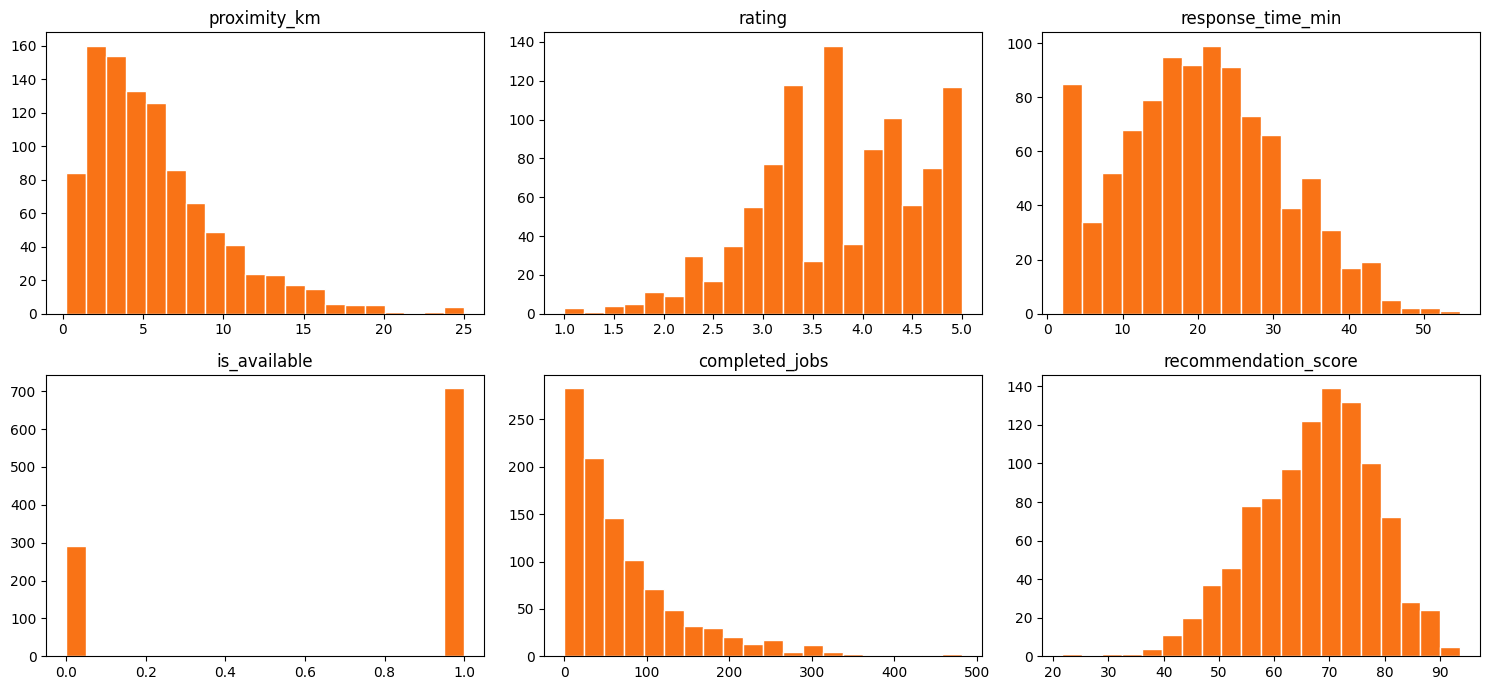

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(ax.ravel(), FEATURES + [TARGET]):
    a.hist(df[c], bins=20, color="#F97316", edgecolor="white"); a.set_title(c)
plt.tight_layout(); plt.savefig("fig_dataset_distribution.png", dpi=150); plt.show()

In [4]:
X = df[FEATURES].values.astype(float); y = df[TARGET].values
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.1765, random_state=42)
scaler = MinMaxScaler().fit(X_train)
S = scaler.transform
print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}")

train=699  val=151  test=150


In [5]:
results, best = [], None
for n in [100, 200, 300]:
    for d in [6, 8, 12, None]:
        m = RandomForestRegressor(n_estimators=n, max_depth=d, min_samples_leaf=2, random_state=42, n_jobs=-1)
        m.fit(S(X_train), y_train)
        mae = mean_absolute_error(y_val, m.predict(S(X_val)))
        results.append({"n_estimators": n, "max_depth": d, "val_MAE": round(mae, 3)})
        if best is None or mae < best[0]: best = (mae, n, d, m)
display(pd.DataFrame(results).sort_values("val_MAE").head(6))
rf = best[3]; print("Selected: n_estimators =", best[1], " max_depth =", best[2])
lin = LinearRegression().fit(S(X_train), y_train)

,n_estimators,max_depth,val_MAE
10,300,12.0,2.792
11,300,NaN,2.795
7,200,NaN,2.802
6,200,12.0,2.806
3,100,NaN,2.840
2,100,12.0,2.848


Selected: n_estimators = 300  max_depth = 12


In [6]:
def reg_metrics(model):
    p = model.predict(S(X_test))
    return {"MAE": mean_absolute_error(y_test, p), "RMSE": float(np.sqrt(mean_squared_error(y_test, p))),
            "R2": r2_score(y_test, p), "Spearman": spearmanr(y_test, p)[0]}
table = pd.DataFrame({"Linear regression (baseline)": reg_metrics(lin), "Random Forest (selected)": reg_metrics(rf)}).T.round(4)
display(table)
cv = cross_val_score(RandomForestRegressor(n_estimators=best[1], max_depth=best[2], min_samples_leaf=2, random_state=42, n_jobs=-1),
                     S(np.vstack([X_train, X_val])), np.concatenate([y_train, y_val]), cv=5, scoring="r2")
print(f"5-fold CV R2 on train+val: {cv.mean():.4f} +/- {cv.std():.4f}")

,MAE,RMSE,R2,Spearman
Linear regression (baseline),1.9872,2.4728,0.9438,0.9677
Random Forest (selected),2.4286,3.0008,0.9173,0.9547


5-fold CV R2 on train+val: 0.8923 +/- 0.0129


Tier accuracy 0.8600 | macro precision 0.9099 | macro recall 0.7718 | macro F1 0.8148
              precision    recall  f1-score   support

         Low       1.00      0.54      0.70        13
      Medium       0.80      0.94      0.86        71
        High       0.93      0.83      0.88        66

    accuracy                           0.86       150
   macro avg       0.91      0.77      0.81       150
weighted avg       0.87      0.86      0.86       150



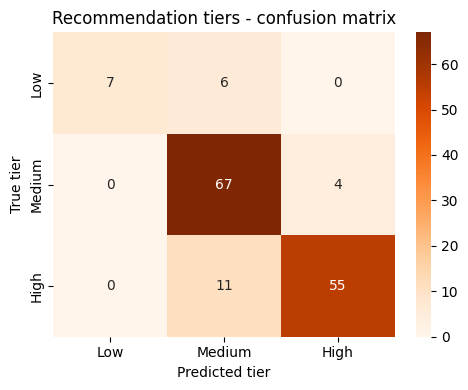

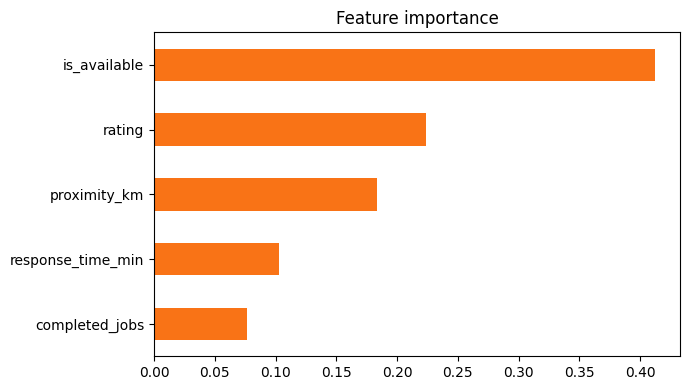

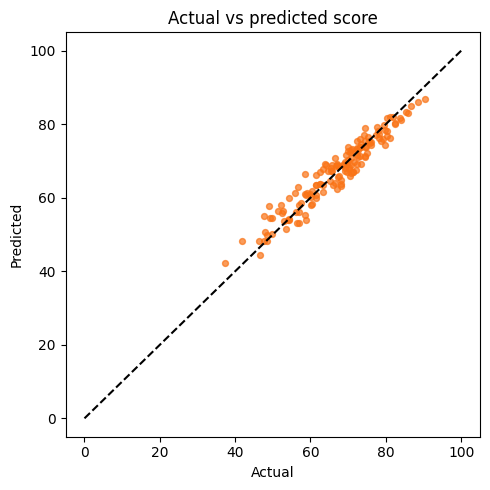

In [7]:
tier = lambda s: np.where(s >= 70, "High", np.where(s >= 50, "Medium", "Low"))
pred = rf.predict(S(X_test)); yt, yp = tier(y_test), tier(pred); labels = ["Low", "Medium", "High"]
acc = accuracy_score(yt, yp)
p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=labels, average="macro", zero_division=0)
print(f"Tier accuracy {acc:.4f} | macro precision {p:.4f} | macro recall {r:.4f} | macro F1 {f:.4f}")
print(classification_report(yt, yp, labels=labels, zero_division=0))
cm = confusion_matrix(yt, yp, labels=labels)
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted tier"); plt.ylabel("True tier"); plt.title("Recommendation tiers - confusion matrix")
plt.tight_layout(); plt.savefig("fig_tier_confusion_matrix.png", dpi=150); plt.show()

imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(7, 4)); imp.plot.barh(color="#F97316"); plt.title("Feature importance")
plt.tight_layout(); plt.savefig("fig_feature_importance.png", dpi=150); plt.show()
plt.figure(figsize=(5, 5)); plt.scatter(y_test, pred, s=18, color="#F97316", alpha=.7)
plt.plot([0, 100], [0, 100], "k--"); plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs predicted score")
plt.tight_layout(); plt.savefig("fig_actual_vs_predicted.png", dpi=150); plt.show()

In [8]:
rng = np.random.default_rng(7)
idx_all = np.arange(len(X_test)); res = {"Random Forest": [], "Nearest mechanic": [], "Highest rating": [], "Random pick": []}
for _ in range(500):
    c = rng.choice(idx_all, 8, replace=False); truth = y_test[c]
    picks = {"Random Forest": int(np.argmax(rf.predict(S(X_test[c])))), "Nearest mechanic": int(np.argmin(X_test[c, 0])),
             "Highest rating": int(np.argmax(X_test[c, 1])), "Random pick": int(rng.integers(8))}
    for k, i in picks.items(): res[k].append((truth[i] == truth.max(), truth.max() - truth[i]))
rank_tbl = pd.DataFrame({k: {"Picked the best mechanic (%)": 100 * np.mean([w for w, _ in v]), "Mean score gap to best": np.mean([g for _, g in v])}
                         for k, v in res.items()}).T.round(2)
display(rank_tbl)

,Picked the best mechanic (%),Mean score gap to best
Random Forest,81.4,0.42
Nearest mechanic,24.6,10.31
Highest rating,31.4,8.25
Random pick,13.8,13.51


In [9]:
print("Rubric used to label the synthetic data (0-100):")
print("  proximity  : max(0, 1 - km/20) x 25")
print("  rating     : (rating/5) x 30")
print("  response   : max(0, 1 - minutes/60) x 20")
print("  available  : is_available x 15")
print("  history    : min(completed_jobs/200, 1) x 10")
print("Normalisation: MinMax scaling fitted on the training split only")
for n, lo, hi in zip(FEATURES, scaler.data_min_, scaler.data_max_): print(f"  {n:18s} min={lo:8.2f}  max={hi:8.2f}")
print("Production rule: unavailable / unverified / suspended mechanics are EXCLUDED before scoring; +5 bonus if specialisation matches the problem; unrated mechanics use a neutral rating of 3.5.")

Rubric used to label the synthetic data (0-100):
  proximity  : max(0, 1 - km/20) x 25
  rating     : (rating/5) x 30
  response   : max(0, 1 - minutes/60) x 20
  available  : is_available x 15
  history    : min(completed_jobs/200, 1) x 10
Normalisation: MinMax scaling fitted on the training split only
  proximity_km       min=    0.20  max=   25.00
  rating             min=    1.00  max=    5.00
  response_time_min  min=    2.00  max=   51.10
  is_available       min=    0.00  max=    1.00
  completed_jobs     min=    0.00  max=  477.00
Production rule: unavailable / unverified / suspended mechanics are EXCLUDED before scoring; +5 bonus if specialisation matches the problem; unrated mechanics use a neutral rating of 3.5.


In [10]:
scen = {"Close, top-rated, fast, available": [0.8, 4.9, 5, 1, 312], "Far, low rating, slow": [15, 2.1, 45, 1, 8],
        "Close, good, but unavailable": [1.0, 4.7, 8, 0, 200], "Mid distance, experienced": [2.5, 4.3, 7, 1, 450]}
for k, v in scen.items(): print(f"{k:38s} -> {rf.predict(S([v]))[0]:6.2f} / 100")

Close, top-rated, fast, available      ->  91.32 / 100
Far, low rating, slow                  ->  51.38 / 100
Close, good, but unavailable           ->  76.37 / 100
Mid distance, experienced              ->  87.94 / 100


In [11]:
os.makedirs("export", exist_ok=True)
pickle.dump(rf, open("export/recommendation_model.pkl", "wb")); pickle.dump(scaler, open("export/recommendation_scaler.pkl", "wb"))
info = {"ranking_test": rank_tbl.to_dict(), "sklearn_version": sklearn.__version__, "features": FEATURES, "tier_thresholds": {"high": 70, "medium": 50},
        "selected": {"n_estimators": best[1], "max_depth": best[2]}, "test_metrics": table.loc["Random Forest (selected)"].to_dict(),
        "tier_accuracy": acc, "tier_macro_f1": f, "trained_on": "synthetic rubric-labelled data"}
json.dump(info, open("export/model_info.json", "w"), indent=2)
for f_ in os.listdir("."):
    if f_.startswith("fig_"): shutil.copy(f_, "export/")
shutil.make_archive("recommendation_export", "zip", "export"); files.download("recommendation_export.zip")
print("Done. Unzip: put the two .pkl files + model_info.json in backend/models/. Keep the fig_*.png for Chapter 5.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done. Unzip: put the two .pkl files + model_info.json in backend/models/. Keep the fig_*.png for Chapter 5.
